# Assignment 03: Image Segmentation and Morphological Processing

**Name:** Erlangga Mandala Putra
**Student ID:** 25/554848/PA/23244

## Objective
Implement Otsu thresholding and morphological operations manually,
then compare segmentation results before and after morphological processing.

## Methods
- Otsu thresholding
- Erosion
- Dilation
- Opening
- Closing

Saving input_text.png to input_text.png


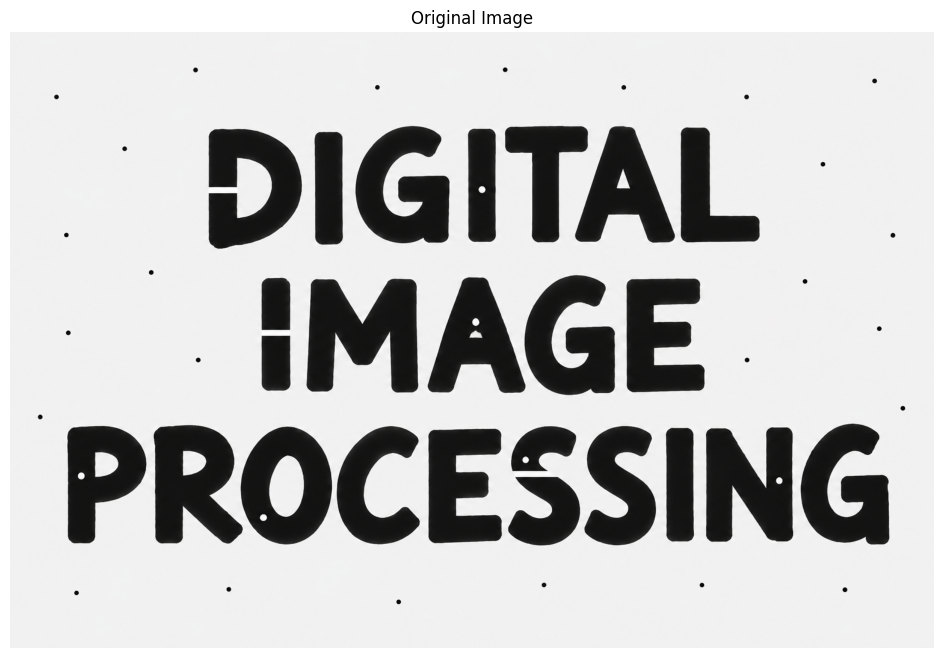

Filename: input_text.png
Image dimensions: (1024, 1536, 3)


In [1]:
from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Upload the input image
uploaded = files.upload()
filename = next(iter(uploaded))

# Read the image
image = Image.open(filename).convert("RGB")
image_rgb = np.array(image)

# Display the input image
plt.figure(figsize=(12, 8))
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")
plt.show()

print("Filename:", filename)
print("Image dimensions:", image_rgb.shape)

## 1. Grayscale Conversion

The RGB image is converted to grayscale manually using:
Gray = 0.299R + 0.587G + 0.114B.

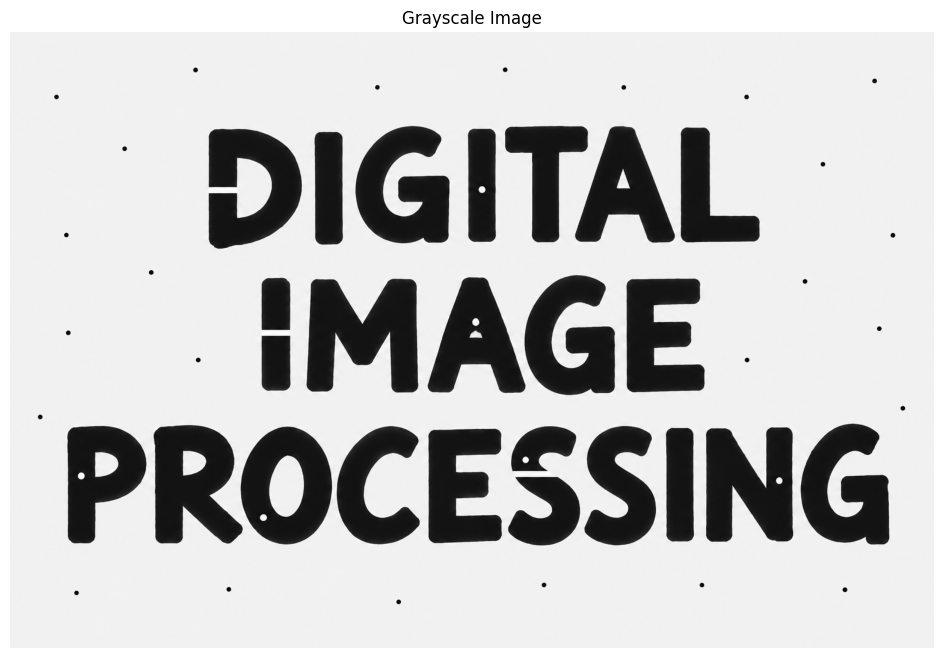

Grayscale dimensions: (1024, 1536)
Minimum intensity: 0
Maximum intensity: 255


In [2]:
# Convert to float before performing calculations
rgb = image_rgb.astype(np.float64)

# Manual RGB-to-grayscale conversion
gray = (
    0.299 * rgb[:, :, 0]
    + 0.587 * rgb[:, :, 1]
    + 0.114 * rgb[:, :, 2]
)

gray = np.clip(np.rint(gray), 0, 255).astype(np.uint8)

# Display the grayscale image
plt.figure(figsize=(12, 8))
plt.imshow(gray, cmap="gray", vmin=0, vmax=255)
plt.title("Grayscale Image")
plt.axis("off")
plt.show()

print("Grayscale dimensions:", gray.shape)
print("Minimum intensity:", gray.min())
print("Maximum intensity:", gray.max())

## 2. Manual Otsu Thresholding

Otsu's method selects the threshold that maximizes the between-class
variance. Dark pixels are assigned as foreground (1), while bright
pixels are assigned as background (0).

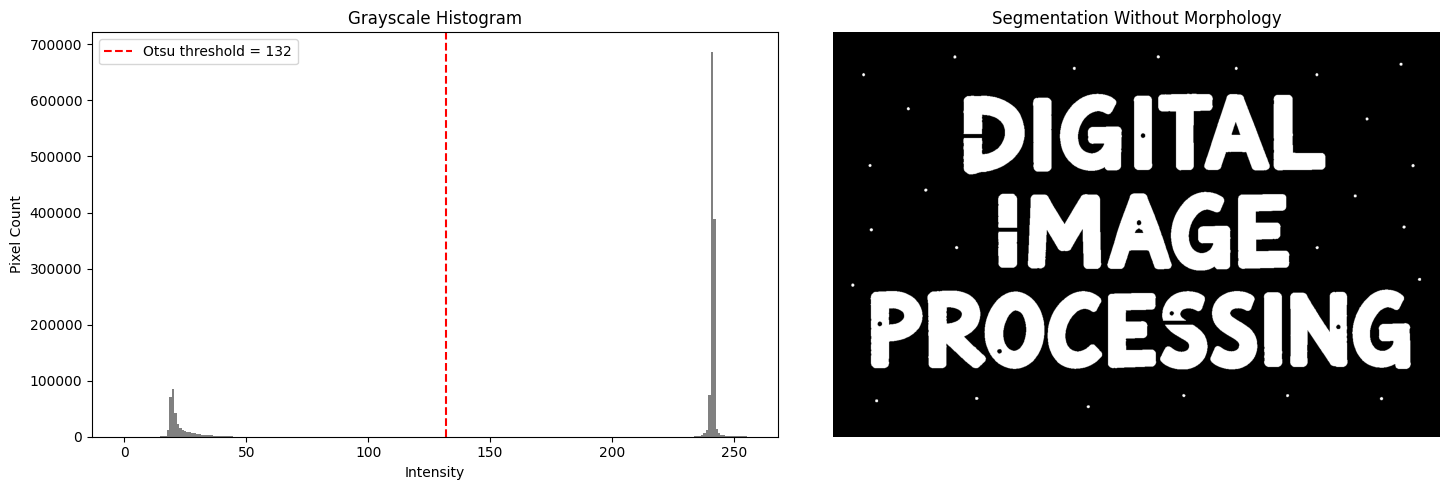

Otsu threshold: 132
Foreground pixels: 348742


In [3]:
def otsu_manual(gray_image):
    # Build the histogram manually
    histogram = [0] * 256
    for pixel in gray_image.flat:
        histogram[int(pixel)] += 1

    total_pixels = gray_image.size
    total_sum = sum(i * histogram[i] for i in range(256))

    background_count = 0
    background_sum = 0
    best_variance = -1
    best_threshold = 0

    for t in range(256):
        background_count += histogram[t]
        background_sum += t * histogram[t]

        if background_count == 0:
            continue

        foreground_count = total_pixels - background_count
        if foreground_count == 0:
            break

        mean_low = background_sum / background_count
        mean_high = (total_sum - background_sum) / foreground_count

        # Proportional to the between-class variance
        variance = (
            background_count
            * foreground_count
            * (mean_low - mean_high) ** 2
        )

        if variance > best_variance:
            best_variance = variance
            best_threshold = t

    return best_threshold, histogram


threshold, histogram = otsu_manual(gray)

# Dark text becomes foreground (1)
binary = (gray <= threshold).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].bar(range(256), histogram, width=1, color="gray")
axes[0].axvline(
    threshold, color="red", linestyle="--",
    label=f"Otsu threshold = {threshold}"
)
axes[0].set_title("Grayscale Histogram")
axes[0].set_xlabel("Intensity")
axes[0].set_ylabel("Pixel Count")
axes[0].legend()

axes[1].imshow(binary, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Segmentation Without Morphology")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Otsu threshold:", threshold)
print("Foreground pixels:", int(binary.sum()))

## 3. Manual Erosion and Dilation

A square 9×9 structuring element is used.

- Erosion keeps a foreground pixel only if all pixels under the
  structuring element are foreground.
- Dilation produces a foreground pixel if at least one pixel under
  the structuring element is foreground.

Pixels outside the image are treated as background (0).

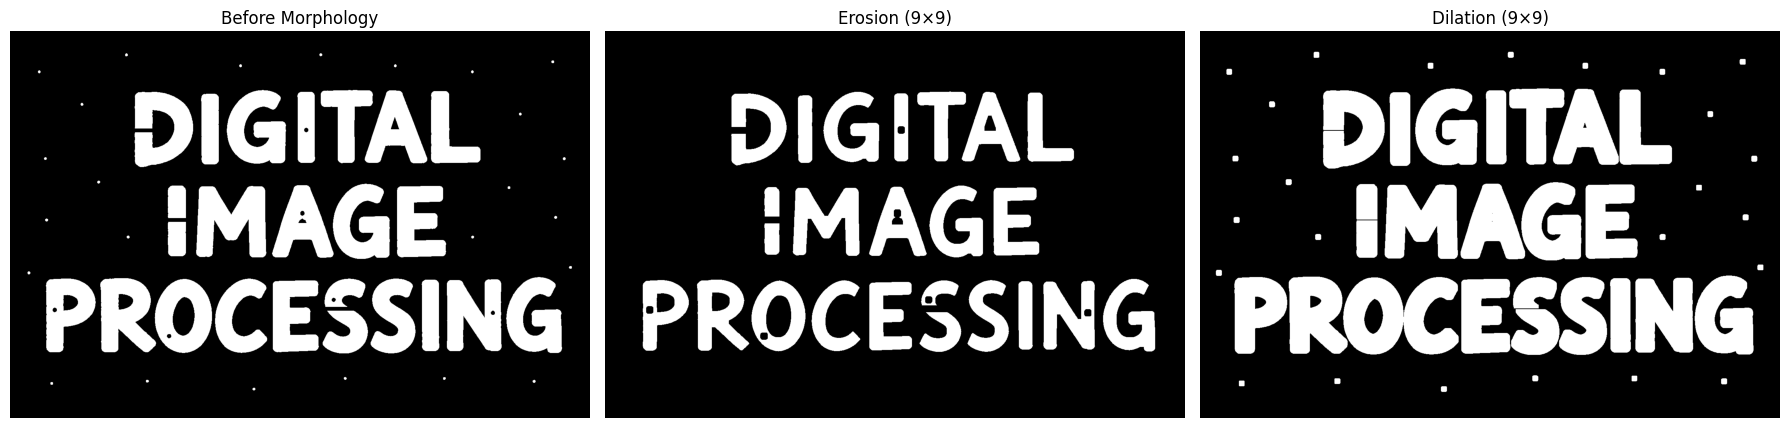

Original foreground pixels: 348742
After erosion: 269601
After dilation: 432679


In [4]:
def erosion_manual(binary_image, kernel_size=9):
    if kernel_size < 1 or kernel_size % 2 == 0:
        raise ValueError("Kernel size must be a positive odd integer.")

    height, width = binary_image.shape
    pad = kernel_size // 2
    padded = np.pad(binary_image, pad, mode="constant",
                    constant_values=0)

    result = np.ones((height, width), dtype=np.uint8)

    # A square structuring element: all positions are active
    for row in range(kernel_size):
        for col in range(kernel_size):
            shifted = padded[row:row + height, col:col + width]
            result = result & shifted

    return result


def dilation_manual(binary_image, kernel_size=9):
    if kernel_size < 1 or kernel_size % 2 == 0:
        raise ValueError("Kernel size must be a positive odd integer.")

    height, width = binary_image.shape
    pad = kernel_size // 2
    padded = np.pad(binary_image, pad, mode="constant",
                    constant_values=0)

    result = np.zeros((height, width), dtype=np.uint8)

    for row in range(kernel_size):
        for col in range(kernel_size):
            shifted = padded[row:row + height, col:col + width]
            result = result | shifted

    return result


kernel_size = 9

eroded = erosion_manual(binary, kernel_size)
dilated = dilation_manual(binary, kernel_size)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

images = [binary, eroded, dilated]
titles = [
    "Before Morphology",
    "Erosion (9×9)",
    "Dilation (9×9)"
]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Original foreground pixels:", int(binary.sum()))
print("After erosion:", int(eroded.sum()))
print("After dilation:", int(dilated.sum()))

## 4. Manual Opening and Closing

- Opening applies erosion followed by dilation to remove small
  foreground noise while approximately preserving larger objects.
- Closing applies dilation followed by erosion to fill small holes
  and connect narrow gaps.

Both operations use the same square 9×9 structuring element.
Each operation is applied independently to the original binary image.

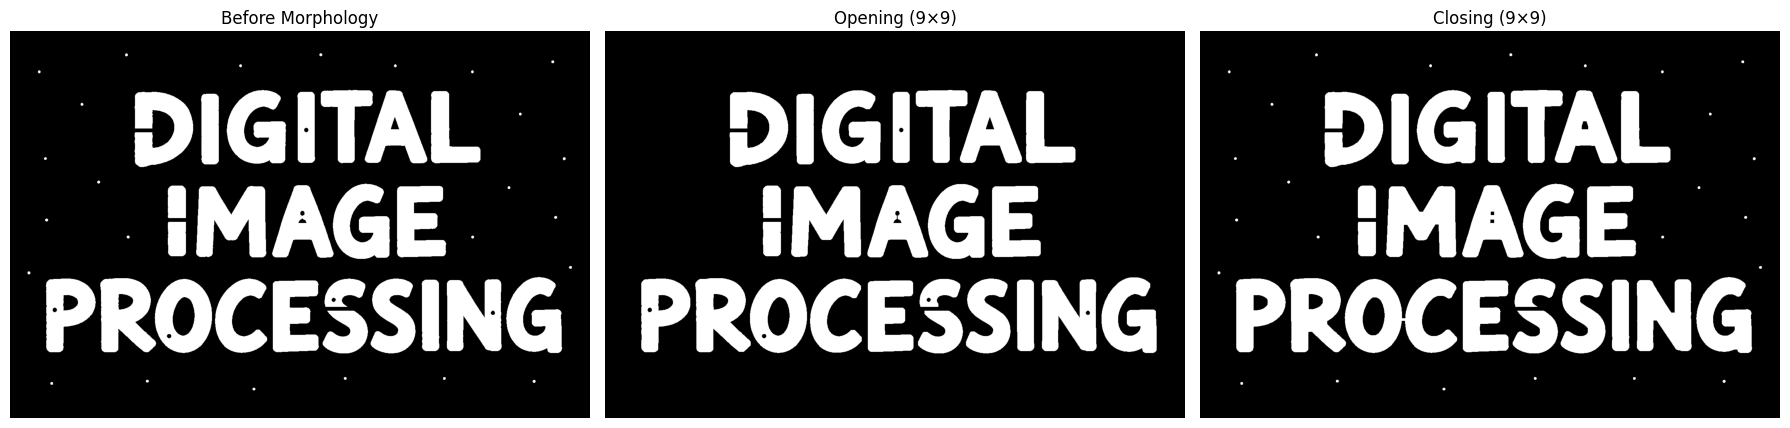

Original foreground pixels: 348742
After opening: 346905
After closing: 350255


In [5]:
def opening_manual(binary_image, kernel_size=9):
    eroded_image = erosion_manual(binary_image, kernel_size)
    return dilation_manual(eroded_image, kernel_size)


def closing_manual(binary_image, kernel_size=9):
    dilated_image = dilation_manual(binary_image, kernel_size)
    return erosion_manual(dilated_image, kernel_size)


opened = opening_manual(binary, kernel_size)
closed = closing_manual(binary, kernel_size)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

images = [binary, opened, closed]
titles = [
    "Before Morphology",
    f"Opening ({kernel_size}×{kernel_size})",
    f"Closing ({kernel_size}×{kernel_size})"
]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Original foreground pixels:", int(binary.sum()))
print("After opening:", int(opened.sum()))
print("After closing:", int(closed.sum()))

## 5. Combined Processing and Kernel Comparison

Opening is followed by closing to remove isolated foreground noise
and repair small background holes and gaps.

Square structuring elements of sizes 9×9 and 15×15 are compared
to observe the effect of kernel size.

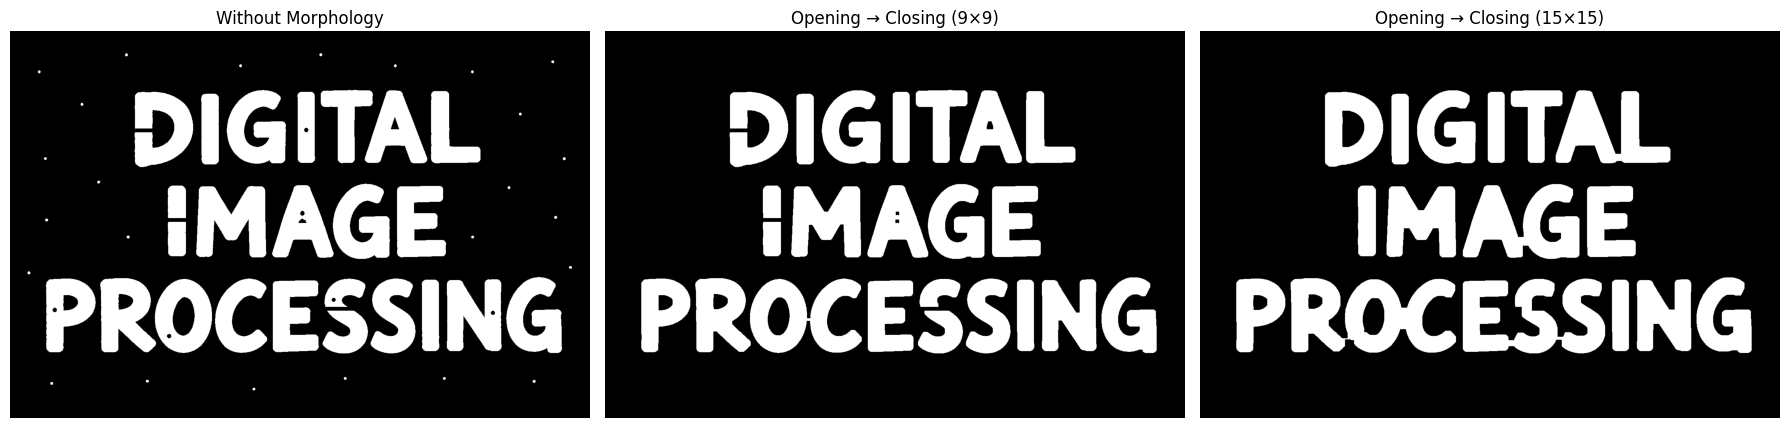

Original foreground pixels: 348742
Opening → Closing (9×9): 348257
Opening → Closing (15×15): 351635


In [6]:
# Apply opening followed by closing
cleaned_9 = closing_manual(opening_manual(binary, 9), 9)
cleaned_15 = closing_manual(opening_manual(binary, 15), 15)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

images = [binary, cleaned_9, cleaned_15]
titles = [
    "Without Morphology",
    "Opening → Closing (9×9)",
    "Opening → Closing (15×15)"
]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Original foreground pixels:", int(binary.sum()))
print("Opening → Closing (9×9):", int(cleaned_9.sum()))
print("Opening → Closing (15×15):", int(cleaned_15.sum()))

## 6. Results and Discussion

Otsu thresholding selected a threshold of 132. It separated the dark
text from the bright background, but isolated noise, small holes,
and broken strokes remained.

| Operation | Foreground pixels | Observation |
|---|---:|---|
| Without morphology | 348,742 | Noise, holes, and broken strokes remained. |
| Erosion (9×9) | 269,601 | Removed small noise but made letters thinner and gaps wider. |
| Dilation (9×9) | 432,679 | Thickened letters and enlarged noise. |
| Opening (9×9) | 346,905 | Removed isolated noise while largely preserving letter thickness. |
| Closing (9×9) | 350,255 | Filled some small defects, but larger gaps remained. |
| Opening then closing (9×9) | 348,257 | Removed noise, but some holes and gaps remained. |
| Opening then closing (15×15) | 351,635 | Repaired more defects, but also joined some neighboring letters. |

The 15×15 combination produced a cleaner result for this image,
but changed some letter boundaries. The 9×9 combination preserved
separation better, although it repaired fewer defects.

Foreground pixel counts describe changes in area; they do not
measure segmentation accuracy. No ground-truth mask was available,
so the comparison was based on visual inspection.

## 7. Conclusion

Otsu thresholding and four morphological operations were implemented
manually. Opening was useful for removing isolated foreground noise,
while closing repaired small holes and gaps. Kernel size affected
the balance between removing defects and preserving letter shapes.

## Image Source and Implementation Notes

The input is an AI-generated synthetic text image containing
intentional noise, holes, and broken strokes.

NumPy was used for array handling and basic arithmetic and logical
operations, Pillow for image loading, and Matplotlib for visualization.
No ready-made segmentation or morphology functions were used.